# mlkit: notebook kiểm thử toàn bộ chức năng

Notebook này chạy **mọi công đoạn** của package, mỗi công đoạn có kiểm tra (`check`) xác nhận kết quả đúng như
mong đợi. Nếu một kiểm tra sai, notebook dừng ngay tại đó và báo rõ lý do.

| # | Công đoạn | # | Công đoạn |
|---|---|---|---|
| 1 | Dữ liệu và cấu hình | 11 | Pipeline và huấn luyện trọn gói |
| 2 | Profile (kiểu ngữ nghĩa) | 12 | Đóng gói (bundle) |
| 3 | Kiểm tra chất lượng (QC) | 13 | Dự đoán |
| 4 | EDA | 14 | Giám sát drift và đánh giá khi có nhãn |
| 5 | Trực quan hóa | 15 | REST API |
| 6 | Tiền xử lý | 16 | MLflow |
| 7 | Tạo đặc trưng | 17 | Dòng lệnh (CLI) |
| 8 | Chọn đặc trưng | 18 | Mở rộng: bước tự viết |
| 9 | Mô hình | 19 | Độ bền với dữ liệu lạ |
| 10 | Đánh giá | 20 | Benchmark tính tổng quát |
| 13b | Tối ưu tham số và giải thích (v0.4) | | |
| 13c | Ensemble, preset và ngân sách thời gian (v0.5) | | |
| 13d | Dự báo chuỗi thời gian (v0.6) | | |
| 13e | Dữ liệu lớn, văn bản ngữ nghĩa, nhiều bảng (v0.7–v0.8) | | |

Chạy từ thư mục gốc của repo, với môi trường đã cài đủ extras (`uv sync --all-extras`). Thời gian chạy khoảng vài
phút. Notebook cũng được CI chạy lại (`pytest -m docs`).

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore")
# chạy từ thư mục gốc repo (nếu notebook được mở trong notebooks/ thì lùi một cấp)
if not Path("examples/data/adult.csv").exists() and Path("../examples/data/adult.csv").exists():
    os.chdir("..")

import mlkit

OUT = Path("artifacts/notebook")
OUT.mkdir(parents=True, exist_ok=True)
RESULTS: list[dict] = []
SECTION = "0. setup"


def check(name, condition, detail=""):
    """Ghi lại một kiểm tra; dừng notebook nếu sai."""
    RESULTS.append({"section": SECTION, "check": name, "passed": bool(condition), "detail": str(detail)[:120]})
    assert condition, f"[{SECTION}] {name}: {detail}"
    print(f"✓ {name}" + (f"  ({detail})" if detail != "" else ""))


rng = np.random.default_rng(42)
check("mlkit import được", True, f"version {mlkit.__version__}")

✓ mlkit import được  (version 0.6.0)


## 1. Dữ liệu và cấu hình
`read_table`, `TaskConfig` (YAML), `prepare_target` (nhị phân / nhiều lớp / hồi quy), `split_data` (phân tầng / thời gian / nhóm).

In [2]:
SECTION = "1. dữ liệu & cấu hình"
from mlkit.core import TaskConfig
from mlkit.runner import prepare_target, read_table, split_data, write_table

adult = read_table("examples/data/adult.csv").sample(3000, random_state=0).reset_index(drop=True)
housing = read_table("examples/data/california_housing.csv").sample(3000, random_state=0).reset_index(drop=True)
check("read_table đọc CSV", adult.shape[1] == 15 and len(housing) == 3000, adult.shape)

write_table(adult.head(50), OUT / "adult_head.parquet")
check("write_table/read_table Parquet khứ hồi", read_table(OUT / "adult_head.parquet").shape == (50, 15))

cfg_bin = TaskConfig(target="class", cv_folds=3, modelling={"positive_label": ">50K", "candidates": ["linear", "lightgbm"]})
cfg_bin.to_yaml(OUT / "cfg.yaml")
check("TaskConfig YAML khứ hồi", TaskConfig.from_yaml(OUT / "cfg.yaml") == cfg_bin)
try:
    TaskConfig(target="y", test_size=1.5)
    check("cấu hình sai bị từ chối", False)
except ValueError:
    check("cấu hình sai bị từ chối", True, "test_size=1.5")

y_bin, info = prepare_target(adult["class"], cfg_bin)
check("target nhị phân -> 0/1", set(y_bin) == {0, 1} and info["positive_label"] == ">50K", info["label_map"])
y_mc, info_mc = prepare_target(adult["race"], TaskConfig(target="race"))
check("target nhiều lớp -> 0..K-1", info_mc["n_classes"] == y_mc.nunique() > 2, info_mc["label_map"])
y_reg, _ = prepare_target(housing["MedHouseVal"], TaskConfig(task_type="regression", target="MedHouseVal"))
check("target hồi quy -> float", y_reg.dtype == float)

X = adult.drop(columns="class")
s = split_data(X, y_bin, cfg_bin)
check("chia phân tầng giữ tỉ lệ lớp", abs(s.y_train.mean() - s.y_test.mean()) < 0.02, s.strategy)
Xt = X.assign(day=rng.permutation(len(X)))
st = split_data(Xt, y_bin, TaskConfig(target="class", time_col="day"))
check("chia theo thời gian: test muộn hơn train", st.X_train["day"].max() < st.X_test["day"].min(), st.strategy)
Xg = X.assign(cust=rng.integers(0, 300, len(X)))
sg = split_data(Xg, y_bin, TaskConfig(target="class", group_col="cust"))
check("chia theo nhóm: không trùng nhóm", not set(sg.X_train["cust"]) & set(sg.X_test["cust"]), sg.strategy)

✓ read_table đọc CSV  ((3000, 15))
✓ write_table/read_table Parquet khứ hồi
✓ TaskConfig YAML khứ hồi
✓ cấu hình sai bị từ chối  (test_size=1.5)
✓ target nhị phân -> 0/1  ({'<=50K': 0, '>50K': 1})
✓ target nhiều lớp -> 0..K-1  ({'Amer-Indian-Eskimo': 0, 'Asian-Pac-Islander': 1, 'Black': 2, 'Other': 3, 'White': 4})
✓ target hồi quy -> float
✓ chia phân tầng giữ tỉ lệ lớp  (stratified)
✓ chia theo thời gian: test muộn hơn train  (time)
✓ chia theo nhóm: không trùng nhóm  (group)


## 2. Profile: nhận diện kiểu ngữ nghĩa
`profile_dataframe`, `infer_column`, `ProfileOptions(overrides=...)`, `apply_coercion`.

In [3]:
SECTION = "2. profile"
from mlkit.qc_eda import ProfileOptions, infer_column, profile_dataframe
from mlkit.qc_eda.profile import apply_coercion

n = 300
messy = pd.DataFrame({
    "customer_id": [f"C{i:05d}" for i in range(n)],
    "price": [f"${v:,.2f}" if i % 9 else "n/a" for i, v in enumerate(rng.uniform(10, 5000, n))],
    "member": rng.choice(["Yes", "No"], n),
    "signup": pd.date_range("2023-01-01", periods=n, freq="D").strftime("%d/%m/%Y"),
    "order_day": rng.choice([20240101, 20240215, 20231231], n),
    "ts": pd.date_range("2024-01-01", periods=n, freq="h", tz="Asia/Ho_Chi_Minh"),
    "zip": [f"{v:05d}" for v in rng.integers(0, 60, n)],
    "duration": pd.to_timedelta(rng.integers(0, 600, n), unit="m"),
    "city": rng.choice([f"city_{i}" for i in range(120)], n),
    "review": [" ".join(rng.choice(["good", "bad", "slow", "fast"], 8)) for _ in range(n)],
    "stars": rng.integers(1, 6, n),
    "const": 1,
})
messy["price_copy"] = messy["price"]
prof = profile_dataframe(messy)
types = {c: p.semantic_type for c, p in prof.columns.items()}
display(prof.to_frame()[["column", "type", "coercion", "missing_rate", "n_unique", "notes"]])

expected = {"customer_id": "identifier", "price": "numeric", "member": "boolean", "signup": "datetime",
            "order_day": "datetime", "ts": "datetime", "duration": "numeric",
            "city": "high_cardinality", "review": "text", "const": "constant"}
for col, t in expected.items():
    check(f"kiểu của '{col}'", types[col] == t, f"{types[col]} (mong đợi {t})")
check("mã có số 0 đầu không bị biến thành số", types["zip"] in ("categorical", "high_cardinality") and prof.columns["zip"].coercion is None, types["zip"])
check("phát hiện cột trùng nội dung", ["price", "price_copy"] in prof.duplicate_columns)
check("'stars' được đánh dấu nhập nhằng", prof.columns["stars"].ambiguous)
check("giá trị thiếu đội lốt được đếm", prof.columns["price"].missing_rate > 0.1)

conv = apply_coercion(messy["price"], "numeric", "numeric")
check("apply_coercion '$1,234.50' -> số", conv.dtype == float and conv.max() <= 5000)
p_override = infer_column(messy["stars"], "stars", ProfileOptions(overrides={"stars": "categorical"}))
check("override kiểu cột", p_override.semantic_type == "categorical" and p_override.overridden)

,column,type,coercion,missing_rate,n_unique,notes
0,customer_id,identifier,None,0.000000,300,
1,price,numeric,numeric,0.113333,266,"34 disguised missing values (e.g. 'n/a', 'null..."
2,member,boolean,boolean,0.000000,2,
3,signup,datetime,datetime,0.000000,300,
4,order_day,datetime,yyyymmdd,0.000000,3,dates stored as numbers (yyyymmdd)
5,ts,datetime,datetime,0.000000,300,timezone Asia/Ho_Chi_Minh converted to UTC
6,zip,high_cardinality,None,0.000000,60,"codes with leading zeros (100% of values, e.g...."
7,duration,numeric,timedelta,0.000000,233,duration converted to seconds
8,city,high_cardinality,None,0.000000,108,
9,review,text,None,0.000000,300,


✓ kiểu của 'customer_id'  (identifier (mong đợi identifier))
✓ kiểu của 'price'  (numeric (mong đợi numeric))
✓ kiểu của 'member'  (boolean (mong đợi boolean))
✓ kiểu của 'signup'  (datetime (mong đợi datetime))
✓ kiểu của 'order_day'  (datetime (mong đợi datetime))
✓ kiểu của 'ts'  (datetime (mong đợi datetime))
✓ kiểu của 'duration'  (numeric (mong đợi numeric))
✓ kiểu của 'city'  (high_cardinality (mong đợi high_cardinality))
✓ kiểu của 'review'  (text (mong đợi text))
✓ kiểu của 'const'  (constant (mong đợi constant))
✓ mã có số 0 đầu không bị biến thành số  (high_cardinality)
✓ phát hiện cột trùng nội dung
✓ 'stars' được đánh dấu nhập nhằng
✓ giá trị thiếu đội lốt được đếm
✓ apply_coercion '$1,234.50' -> số
✓ override kiểu cột


## 3. Kiểm tra chất lượng (QC)
`run_qc`, `QualityCheckStep`, phát hiện rò rỉ (lỗi và cảnh báo), cổng chặn.

In [4]:
SECTION = "3. QC"
from mlkit.core import QualityGateError
from mlkit.qc_eda import QualityCheckStep, run_qc

qc = run_qc(adult.drop(columns="class"), y=adult["class"], enforce_gate=False)
print(qc.report_.summary())
check("điểm chất lượng 0–100", 0 <= qc.data_quality_score_ <= 100, qc.data_quality_score_)
check("không lỗi trên Adult", not qc.report_.has_errors)

qc_messy = run_qc(messy, y=pd.Series(rng.integers(0, 2, len(messy))), enforce_gate=False)
warned = {i.name for i in qc_messy.report_.items if i.status == "warn"}
for name in ["identifier_columns", "text_columns", "disguised_missing", "duplicate_columns", "constant_columns", "ambiguous_types"]:
    check(f"QC cảnh báo '{name}'", name in warned)
display(qc_messy.issues_frame_.head(8))

leaky = adult.assign(leak=y_bin.map({0: "no", 1: "yes"}))
qc_leak = run_qc(leaky.drop(columns="class"), y=y_bin, enforce_gate=False)
check("phát hiện rò rỉ (lỗi)", any(i.name == "data_leakage" and i.status == "error" for i in qc_leak.report_.items))
boat = pd.Series(np.where((y_bin == 1) & (rng.uniform(size=len(y_bin)) < 0.9), rng.integers(1, 20, len(y_bin)), np.nan))
qc_susp = run_qc(adult.drop(columns="class").assign(boat=boat), y=y_bin, enforce_gate=False)
check("cảnh báo rò rỉ qua việc bị thiếu", any(i.name == "leakage_suspect" for i in qc_susp.report_.items))
try:
    QualityCheckStep(enforce_gate=True).fit(leaky.drop(columns="class"), y_bin)
    check("cổng chặn khi có lỗi", False)
except QualityGateError:
    check("cổng chặn khi có lỗi", True, "QualityGateError")

=== Quality Control & EDA Report (Passed: True) ===
  ✅ [data_shape]: Dataset contains 3000 rows and 14 columns (1.7 MB).
  ✅ [duplicates]: Duplicate rows check passed (0 duplicates).
  ✅ [missing_values]: Missing values within acceptable thresholds.
  ✅ [constant_columns]: No constant columns detected.
  ✅ [high_cardinality]: All categorical features have healthy cardinality.
  ⚠️ [outliers]: 1 numeric columns with > 5% extreme values (3 x IQR): ['hours-per-week']
  ✅ [target_distribution]: Target variable has 2 unique values: {'<=50K': 2297, '>50K': 703}
  ✅ [data_leakage]: No obvious target leakage detected.
  ✅ [data_quality_score]: Overall Data Quality Score: 99.4 / 100
✓ điểm chất lượng 0–100  (99.4)
✓ không lỗi trên Adult
✓ QC cảnh báo 'identifier_columns'
✓ QC cảnh báo 'text_columns'
✓ QC cảnh báo 'disguised_missing'
✓ QC cảnh báo 'duplicate_columns'
✓ QC cảnh báo 'constant_columns'
✓ QC cảnh báo 'ambiguous_types'


,column,check,severity,detail,suggestion
0,price_copy,duplicate_columns,warn,identical to 'price',drop the copy
1,customer_id,identifier_columns,warn,100% unique,exclude from features
2,stars,ambiguous_types,warn,"ambiguous: integer with few values - a count, ...",set column_types


✓ phát hiện rò rỉ (lỗi)


✓ cảnh báo rò rỉ qua việc bị thiếu


✓ cổng chặn khi có lỗi  (QualityGateError)


## 4. EDA
`run_eda` với target nhị phân, nhiều lớp, hồi quy và không có target; thước đo liên hệ; báo cáo HTML.

In [5]:
SECTION = "4. EDA"
from mlkit.qc_eda import correlation_ratio, cramers_v, run_eda

eda = run_eda(adult, target="class")
print(eda.summary())
display(eda.target_association.head(5))
check("EDA nhị phân xếp hạng liên hệ", eda.target_kind == "binary" and eda.target_association["strength"].between(0, 1).all())
check("bảng target theo nhóm", "relationship" in eda.target_by_feature)
check("ma trận liên hệ vuông", eda.associations.shape[0] == eda.associations.shape[1] > 1)
html = eda.to_html(OUT / "eda_adult.html")
check("báo cáo HTML", "Data quality" in html and (OUT / "eda_adult.html").exists())

eda_mc = run_eda(adult.drop(columns="class"), target="race", with_qc=False)
check("EDA nhiều lớp", eda_mc.target_kind == "multiclass")
eda_reg = run_eda(housing, target="MedHouseVal", with_qc=False)
check("EDA hồi quy, MedInc đứng đầu", eda_reg.target_kind == "regression" and eda_reg.target_association.iloc[0]["feature"] == "MedInc")
eda_none = run_eda(messy)
check("EDA không có target", eda_none.target_kind is None and eda_none.profile.n_rows == len(messy))

a = pd.Series(rng.choice(list("xyz"), 2000))
check("Cramér's V của cột với chính nó ≈ 1", cramers_v(a, a) > 0.99)
check("tỉ số tương quan η = 1 khi category quyết định giá trị", correlation_ratio(a, a.map({"x": 0, "y": 1, "z": 2}).astype(float)) > 0.99)

Rows: 3,000  Columns: 14  Duplicate rows: 0
Column types: categorical=7, numeric=6, binary=1
Target 'class' (binary)
Top associations: relationship (0.45, cramers_v), marital-status (0.44, cramers_v), education (0.34, cramers_v), occupation (0.34, cramers_v), education-num (0.32, eta)
QC: 1 warnings/errors, quality score 99.4/100


,feature,type,method,strength,n
0,relationship,categorical,cramers_v,0.446605,3000
1,marital-status,categorical,cramers_v,0.437910,3000
2,education,categorical,cramers_v,0.344548,3000
3,occupation,categorical,cramers_v,0.336648,2833
4,education-num,numeric,eta,0.317278,3000


✓ EDA nhị phân xếp hạng liên hệ
✓ bảng target theo nhóm
✓ ma trận liên hệ vuông


✓ báo cáo HTML


✓ EDA nhiều lớp
✓ EDA hồi quy, MedInc đứng đầu


✓ EDA không có target
✓ Cramér's V của cột với chính nó ≈ 1
✓ tỉ số tương quan η = 1 khi category quyết định giá trị


## 5. Trực quan hóa
Biểu đồ dữ liệu (EDA) và biểu đồ mô hình; mọi hàm trả về `Figure`.

✓ biểu đồ 'column_overview'


✓ biểu đồ 'distributions'
✓ biểu đồ 'target_association'
✓ biểu đồ 'target_by_feature'


✓ biểu đồ 'missingness'


✓ biểu đồ 'association_matrix'
✓ biểu đồ 'missing_rates'
✓ biểu đồ 'target_distribution'


✓ biểu đồ 'correlation_heatmap'
✓ biểu đồ 'roc'
✓ biểu đồ 'pr'


✓ biểu đồ 'calibration'
✓ biểu đồ 'confusion'
✓ biểu đồ 'gains'


✓ biểu đồ 'lift'
✓ biểu đồ 'learning_curve'
✓ biểu đồ 'arena'
✓ biểu đồ 'importance'


✓ biểu đồ 'shap'
✓ biểu đồ 'drift_psi'


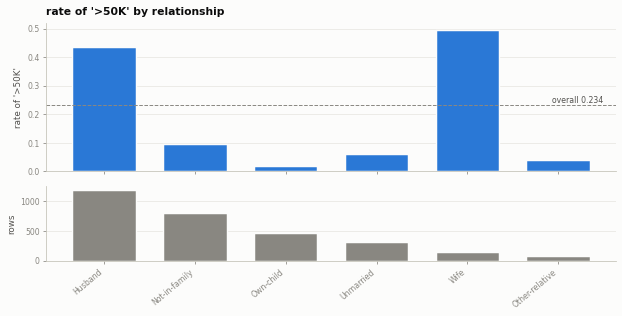

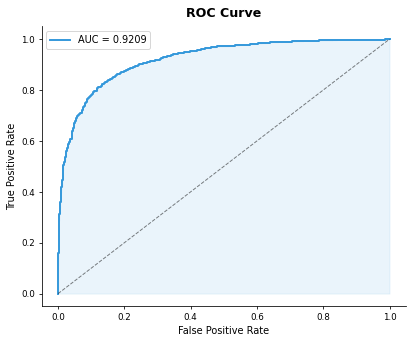

In [6]:
SECTION = "5. trực quan hóa"
from mlkit.modelling import LinearTrainer, ModelArena, RandomForestTrainer
from mlkit.monitoring import DriftMonitor
from mlkit.viz import (plot_arena_comparison, plot_association_matrix, plot_calibration_curve, plot_column_overview,
                       plot_confusion_matrix, plot_correlation_heatmap, plot_cumulative_gains, plot_distributions,
                       plot_drift_psi, plot_feature_importance, plot_learning_curve, plot_lift_curve, plot_missing_rates,
                       plot_missingness, plot_precision_recall_curve, plot_roc_curve, plot_shap_summary,
                       plot_target_association, plot_target_by_feature, plot_target_distribution)

num = housing.drop(columns="MedHouseVal")
yb = (housing["MedHouseVal"] > housing["MedHouseVal"].median()).astype(int).to_numpy()
p = LinearTrainer().fit(num, yb).predict_proba(num)[:, 1]
arena5 = ModelArena(cv=3, candidates=["linear", "random_forest"]).fit(num, yb)
rf = RandomForestTrainer(n_estimators=30).fit(num, yb)
mon5 = DriftMonitor().fit(num)

figs = {
    "column_overview": plot_column_overview(eda.profile),
    "distributions": plot_distributions(eda.analysed, eda.profile, max_columns=6),
    "target_association": plot_target_association(eda),
    "target_by_feature": plot_target_by_feature(eda, "relationship"),
    "missingness": plot_missingness(eda_none) if not eda_none.missingness.empty else plot_column_overview(eda_none.profile),
    "association_matrix": plot_association_matrix(eda),
    "missing_rates": plot_missing_rates(messy),
    "target_distribution": plot_target_distribution(adult["class"]),
    "correlation_heatmap": plot_correlation_heatmap(num),
    "roc": plot_roc_curve(yb, p),
    "pr": plot_precision_recall_curve(yb, p),
    "calibration": plot_calibration_curve(yb, p),
    "confusion": plot_confusion_matrix(yb, (p > 0.5).astype(int)),
    "gains": plot_cumulative_gains(yb, p),
    "lift": plot_lift_curve(yb, p),
    "learning_curve": plot_learning_curve(LinearTrainer(), num, yb, cv=3),
    "arena": plot_arena_comparison(arena5),
    "importance": plot_feature_importance(arena5, feature_names=list(num.columns)),
    "shap": plot_shap_summary(rf, num.sample(200, random_state=0)),
    "drift_psi": plot_drift_psi(mon5.monitor(num.assign(MedInc=num["MedInc"] * 2))),
}
for name, fig in figs.items():
    fig.savefig(OUT / f"fig_{name}.png", dpi=70, bbox_inches="tight")
    check(f"biểu đồ '{name}'", hasattr(fig, "savefig"))
plt.close("all")
display(Image(OUT / "fig_target_by_feature.png"))
display(Image(OUT / "fig_roc.png"))

## 6. Tiền xử lý
`TypeCaster`, `MissingImputer`, `RareCategoryGrouper`, `CategoricalEncoder` (target encoding OOF), `FeatureScaler`, `OutlierClipper`.

In [7]:
SECTION = "6. tiền xử lý"
from mlkit.preprocessing import CategoricalEncoder, FeatureScaler, MissingImputer, OutlierClipper, RareCategoryGrouper, TypeCaster

tc = TypeCaster().fit(messy)
Xm = tc.transform(messy)
check("TypeCaster loại ID/hằng/trùng", {"customer_id", "const", "price_copy"} <= set(tc.drop_reasons_), tc.drop_reasons_)
check("TypeCaster chuyển '$..' thành số", Xm["price"].dtype == float)
check("TypeCaster chuyển ngày (có timezone) về naive UTC", str(Xm["ts"].dtype) == "datetime64[ns]")
check("TypeCaster giữ mã có số 0 đầu là category", Xm["zip"].dtype == "category")
check("schema ổn định trên batch mới", list(tc.transform(messy.sample(40, random_state=1)).columns) == list(Xm.columns))

imp = MissingImputer(add_indicator="auto", categorical_strategy="missing_value")
Xi = imp.fit_transform(Xm.select_dtypes(exclude="datetime"))
check("MissingImputer điền hết và tạo cờ", Xi.drop(columns=[c for c in Xi if Xi[c].dtype == object]).isna().sum().sum() == 0 and "price_is_missing" in Xi, imp.indicator_cols_)

rg = RareCategoryGrouper(min_freq=None, min_count=10, max_cardinality=10)
low = pd.DataFrame({"c": ["a"] * 50 + ["b"] * 45 + ["rare"] * 3})
check("RareCategoryGrouper gộp mức hiếm", "__rare__" in set(rg.fit_transform(low)["c"]))

hc = pd.DataFrame({"hc": rng.integers(0, 200, 2000).astype(str)})
y_rand = rng.integers(0, 2, 2000)
enc = CategoricalEncoder(low_card_threshold=5)
oof = enc.fit_transform(hc, y_rand)["hc"].to_numpy()
full = enc.transform(hc)["hc"].to_numpy()
check("target encoding dùng out-of-fold khi fit", enc.encoding_plan_["hc"] == "target" and not np.allclose(oof, full))
check("frequency encoding khi không có target", CategoricalEncoder(low_card_threshold=5).fit(hc).encoding_plan_["hc"] == "frequency")

sc = FeatureScaler().fit_transform(num)
check("FeatureScaler chuẩn hóa", abs(sc.mean().mean()) < 1e-6)
oc = OutlierClipper(factor=1.5).fit(num)
check("OutlierClipper cắt ngoại lai", (oc.transform(num)["AveRooms"] <= oc.bounds_["AveRooms"][1] + 1e-9).all())

✓ TypeCaster loại ID/hằng/trùng  ({'price_copy': "duplicate of 'price'", 'customer_id': 'identifier', 'const': 'constant'})
✓ TypeCaster chuyển '$..' thành số
✓ TypeCaster chuyển ngày (có timezone) về naive UTC
✓ TypeCaster giữ mã có số 0 đầu là category
✓ schema ổn định trên batch mới
✓ MissingImputer điền hết và tạo cờ  (['price'])
✓ RareCategoryGrouper gộp mức hiếm
✓ target encoding dùng out-of-fold khi fit
✓ frequency encoding khi không có target
✓ FeatureScaler chuẩn hóa
✓ OutlierClipper cắt ngoại lai


## 7. Tạo đặc trưng
`DatetimeFeatures`, `TextFeatures`, `RatioFeatures`, `GroupAggFeatures`, `BinningFeatures`, `MultiTableAggregator`, và bộ đặc trưng theo thời điểm (`TemporalSpec`, `build_panel`, `build_features`, `build_labels`).

In [8]:
SECTION = "7. đặc trưng"
from mlkit.features import (BinningFeatures, DatetimeFeatures, GroupAggFeatures, MultiTableAggregator, RatioFeatures,
                            TemporalSpec, TextFeatures, build_features, build_labels, build_panel)

dt = DatetimeFeatures().fit_transform(Xm[["signup", "ts"]])
check("DatetimeFeatures tách thành phần lịch", {"signup_month", "signup_dayofweek", "ts_year"} <= set(dt.columns))
tx = TextFeatures().fit_transform(messy[["review"]])
check("TextFeatures thay văn bản bằng thống kê", "review" not in tx and (tx["review_n_words"] == 8).all())
rt = RatioFeatures(pairs=[("AveRooms", "AveBedrms")]).fit_transform(num)
check("RatioFeatures", "AveRooms_div_AveBedrms" in rt)
ga = GroupAggFeatures(group_cols=["workclass"], target_cols=["age"]).fit_transform(adult)
check("GroupAggFeatures", "workclass_age_mean" in ga)
bn = BinningFeatures(columns=["age"], n_bins=5).fit_transform(adult)
check("BinningFeatures", bn["age_bin"].nunique() == 5)
primary = pd.DataFrame({"acc": range(100)})
tx_tbl = pd.DataFrame({"acc": rng.integers(0, 100, 1000), "amount": rng.gamma(2, 10, 1000)})
mt = MultiTableAggregator(secondary_df=tx_tbl, join_key="acc").fit_transform(primary)
check("MultiTableAggregator tổng hợp bảng phụ", "rel_amount_sum" in mt and len(mt) == 100)

cust, day = np.nonzero(rng.uniform(size=(200, 300)) < rng.uniform(0.02, 0.4, 200)[:, None])
events = pd.DataFrame({"customer": cust, "day": day + 1, "amount": rng.gamma(2, 20, len(cust)), "basket": np.arange(len(cust))})
spec = TemporalSpec(entity_col="customer", time_col="day", windows=(7, 28), sum_cols=("amount",), nunique_cols=("basket",))
panel = build_panel(events, cutoffs=range(60, 290, 7), horizon=7, spec=spec)
now = build_features(events, as_of=250, spec=spec)
future = pd.DataFrame({"customer": [0], "day": [251], "amount": [1e9], "basket": [-1]})
check("build_features không đọc dữ liệu tương lai", build_features(pd.concat([events, future]), as_of=250, spec=spec).equals(now))
labels = build_labels(events, as_of=250, horizon=7, spec=spec, entities=now.index)
check("build_panel/build_labels", {"cutoff", "target", "recency_days"} <= set(panel.columns) and labels.isin([0, 1]).all(), panel.shape)

✓ DatetimeFeatures tách thành phần lịch
✓ TextFeatures thay văn bản bằng thống kê
✓ RatioFeatures
✓ GroupAggFeatures
✓ BinningFeatures
✓ MultiTableAggregator tổng hợp bảng phụ


✓ build_features không đọc dữ liệu tương lai
✓ build_panel/build_labels  ((6272, 17))


## 8. Chọn đặc trưng
`VarianceFilter`, `CorrelationFilter`, `MutualInformationSelector`, `ModelImportanceSelector`.

In [9]:
SECTION = "8. chọn đặc trưng"
from mlkit.selection import CorrelationFilter, ModelImportanceSelector, MutualInformationSelector, VarianceFilter

Xs = num.assign(const=1.0, copy=num["MedInc"] * 2 + 1e-6 * rng.normal(size=len(num)))
check("VarianceFilter bỏ cột hằng", "const" not in VarianceFilter().fit_transform(Xs))
check("CorrelationFilter bỏ cột gần trùng", "copy" not in CorrelationFilter(threshold=0.95).fit_transform(Xs))
mi = MutualInformationSelector(top_k=3).fit(num, yb, cfg=TaskConfig(target="y"))
check("MutualInformationSelector giữ top-k", mi.transform(num).shape[1] == 3, list(mi.scores_)[:3])
mis = ModelImportanceSelector(top_k=4).fit(num, yb, cfg=TaskConfig(target="y"))
check("ModelImportanceSelector giữ top-k", len(mis.selected_features_) == 4, mis.selected_features_)

✓ VarianceFilter bỏ cột hằng
✓ CorrelationFilter bỏ cột gần trùng
✓ MutualInformationSelector giữ top-k  (['Longitude', 'MedInc', 'Latitude'])


✓ ModelImportanceSelector giữ top-k  (['MedInc', 'Longitude', 'Latitude', 'AveOccup'])


## 9. Mô hình
Mọi trainer cho nhị phân / nhiều lớp / hồi quy; `ModelArena` (hiệu chuẩn, ngưỡng, candidate mới); `OptunaSearch`; `CalibratedModelWrapper`; `SklearnModelWrapper`.

In [10]:
SECTION = "9. mô hình"
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

from mlkit.modelling import (LGBM_SPACE, CalibratedModelWrapper, DummyTrainer, ExtraTreesTrainer, HistGBTrainer,
                             LGBMTrainer, OptunaSearch, SklearnModelWrapper, XGBTrainer)

Xn = num.iloc[:1500]
y_bin9 = yb[:1500]
y_mc9 = pd.qcut(housing["MedHouseVal"].iloc[:1500], 3, labels=False).to_numpy()
y_reg9 = housing["MedHouseVal"].iloc[:1500].to_numpy()
trainers = {"linear": LinearTrainer, "random_forest": RandomForestTrainer, "lightgbm": LGBMTrainer,
            "xgboost": XGBTrainer, "hist_gb": HistGBTrainer, "extra_trees": ExtraTreesTrainer, "dummy": DummyTrainer}
for name, cls in trainers.items():
    m_bin = clone(cls()).fit(Xn, y_bin9)
    m_mc = clone(cls()).fit(Xn, y_mc9)
    m_reg = cls(task_type="regression").fit(Xn, y_reg9)
    ok = (m_bin.predict_proba(Xn).shape == (1500, 2) and m_mc.predict_proba(Xn).shape == (1500, 3)
          and m_reg.predict(Xn).shape == (1500,))
    check(f"trainer '{name}': nhị phân / nhiều lớp / hồi quy", ok)
check("SklearnModelWrapper", SklearnModelWrapper(LogisticRegression(max_iter=500)).fit(Xn, y_bin9).predict_proba(Xn).shape[1] == 2)

arena = ModelArena(cv=3, candidates=["linear", "lightgbm", "hist_gb", "extra_trees"], handle_imbalance=False,
                   calibration="auto", threshold="f1").fit(Xn, y_bin9, cfg=TaskConfig(target="y"))
display(arena.comparison_table_)
check("ModelArena chọn mô hình thắng baseline", arena.best_model_name_ != "Baseline (Dummy)", arena.best_model_name_)
check("ngưỡng quyết định tối ưu F1", 0 < arena.decision_threshold_ < 1, round(arena.decision_threshold_, 3))
check("hiệu chuẩn chỉ giữ khi Brier giảm", arena.calibration_ in (None, "sigmoid", "isotonic"), arena.calibration_)
arena_mc = ModelArena(cv=3, candidates=["linear", "lightgbm"]).fit(Xn, y_mc9, cfg=TaskConfig(target="y"))
check("ModelArena nhiều lớp", arena_mc.predict_proba(Xn).shape == (1500, 3), arena_mc.best_model_name_)
arena_reg = ModelArena(cv=3, candidates=["linear", "lightgbm"]).fit(Xn, y_reg9, cfg=TaskConfig(task_type="regression", target="y"))
check("ModelArena hồi quy", arena_reg.best_model_name_ == "LightGBM")

search = OptunaSearch(estimator_cls=LGBMTrainer, space=LGBM_SPACE, n_trials=3, cv=3).fit(Xn, y_bin9, cfg=TaskConfig(target="y"))
check("OptunaSearch tìm tham số", "subsample_freq" in search.best_params_ and search.best_score_ > 0.8, round(search.best_score_, 3))
cal = CalibratedModelWrapper(base_estimator=LGBMTrainer(n_estimators=50), method="isotonic").fit(Xn, y_bin9)
check("CalibratedModelWrapper", cal.predict_proba(Xn).shape == (1500, 2))

✓ trainer 'linear': nhị phân / nhiều lớp / hồi quy


✓ trainer 'random_forest': nhị phân / nhiều lớp / hồi quy


✓ trainer 'lightgbm': nhị phân / nhiều lớp / hồi quy


✓ trainer 'xgboost': nhị phân / nhiều lớp / hồi quy


✓ trainer 'hist_gb': nhị phân / nhiều lớp / hồi quy


✓ trainer 'extra_trees': nhị phân / nhiều lớp / hồi quy
✓ trainer 'dummy': nhị phân / nhiều lớp / hồi quy


... (2 outputs left out)

✓ ModelArena chọn mô hình thắng baseline  (Extra Trees)
✓ ngưỡng quyết định tối ưu F1  (0.446)
✓ hiệu chuẩn chỉ giữ khi Brier giảm  (sigmoid)


✓ ModelArena nhiều lớp  (LightGBM)


✓ ModelArena hồi quy


✓ OptunaSearch tìm tham số  (0.941)
✓ CalibratedModelWrapper


## 10. Đánh giá
`compute_metrics` (nhị phân / nhiều lớp / hồi quy), `compute_bootstrap_ci`, `expected_calibration_error`, `optimal_threshold`, `CVEvaluator` (nhóm / thời gian).

In [11]:
SECTION = "10. đánh giá"
from mlkit.modelling import CVEvaluator, compute_bootstrap_ci, compute_metrics, expected_calibration_error
from mlkit.modelling.evaluation import optimal_threshold

pb = LinearTrainer().fit(Xn, y_bin9).predict_proba(Xn)
mb = compute_metrics(y_bin9, pb.argmax(1), pb)
check("metric nhị phân", {"roc_auc", "pr_auc", "log_loss", "brier", "ece", "f1"} <= set(mb), round(mb["roc_auc"], 3))
pm = LinearTrainer().fit(Xn, y_mc9).predict_proba(Xn)
mm = compute_metrics(y_mc9, pm.argmax(1), pm)
check("metric nhiều lớp", {"roc_auc", "log_loss", "brier", "ece"} <= set(mm) and "pr_auc" not in mm, round(mm["roc_auc"], 3))
mr = compute_metrics(y_reg9, LinearTrainer(task_type="regression").fit(Xn, y_reg9).predict(Xn), task_type="regression")
check("metric hồi quy", {"rmse", "mae", "r2"} == set(mr), round(mr["r2"], 3))
ci = compute_bootstrap_ci(y_bin9, pb.argmax(1), pb, n_bootstraps=100)
check("khoảng tin cậy bootstrap", ci["roc_auc"]["ci_lower"] <= mb["roc_auc"] <= ci["roc_auc"]["ci_upper"], ci["roc_auc"])
pp = rng.uniform(size=5000)
check("ECE ≈ 0 với xác suất hoàn hảo", expected_calibration_error((rng.uniform(size=5000) < pp).astype(int), pp) < 0.03)
check("optimal_threshold", 0 < optimal_threshold(y_bin9, pb[:, 1], "youden") < 1)
groups = np.repeat(np.arange(150), 10)
check("CVEvaluator theo nhóm", CVEvaluator(cv=3).evaluate(LinearTrainer(), Xn, y_bin9, groups=groups)["roc_auc_mean"] > 0.8)
check("CVEvaluator theo thời gian", "roc_auc_mean" in CVEvaluator(cv=3).evaluate(LinearTrainer(), Xn, y_bin9, time_index=np.arange(1500)))

✓ metric nhị phân  (0.929)


✓ metric nhiều lớp  (0.842)
✓ metric hồi quy  (0.617)
✓ khoảng tin cậy bootstrap  ({'mean': 0.9291075849036826, 'std': 0.0062873562663058324, 'ci_lower': 0.9168530345309909, 'ci_upper': 0.9401290641462006})
✓ ECE ≈ 0 với xác suất hoàn hảo
✓ optimal_threshold


✓ CVEvaluator theo nhóm


✓ CVEvaluator theo thời gian


## 11. Pipeline và huấn luyện trọn gói
`Pipeline` (CV toàn pipeline chống rò rỉ), route tham số, `train` (nhị phân / nhiều lớp / hồi quy, cổng metric), pipeline từ YAML `steps`.

In [12]:
SECTION = "11. pipeline & train"
from mlkit.core import Pipeline
from mlkit.runner import build_default_pipeline, build_pipeline_from_config, train

noise = pd.DataFrame(rng.normal(size=(300, 300)), columns=[f"f{i}" for i in range(300)])
y_noise = rng.integers(0, 2, 300)
auc = {}
for scope in ("model", "pipeline"):
    ar = ModelArena(cv=4, candidates=["linear"], enforce_baseline_gate=False)
    Pipeline([("sel", ModelImportanceSelector(top_k=10)), ("arena", ar)], cv_scope=scope).fit(noise, y_noise, cfg=TaskConfig(target="y"))
    auc[scope] = ar.cv_results_["Linear Model"]["roc_auc_mean"]
check("CV toàn pipeline loại bỏ rò rỉ do chọn đặc trưng", auc["pipeline"] < 0.6 < auc["model"], {k: round(v, 3) for k, v in auc.items()})

check("pipeline mặc định 12 bước", len(build_default_pipeline(cfg_bin).steps) == 12)
res_bin = train(TaskConfig(target="class", cv_folds=3, metric_thresholds={"roc_auc": 0.85},
                           modelling={"positive_label": ">50K", "candidates": ["linear", "lightgbm"], "threshold": "f1"}),
                adult, output_dir=OUT / "bundle_bin")
check("train nhị phân + cổng metric", res_bin.metrics["thresholds_passed"], {k: round(v, 3) for k, v in res_bin.metrics["holdout"].items() if k in ("roc_auc", "pr_auc", "ece")})
res_mc = train(TaskConfig(target="race", cv_folds=3, modelling={"candidates": ["linear", "lightgbm"]}),
               adult.drop(columns="class"), output_dir=OUT / "bundle_mc")
check("train nhiều lớp", res_mc.metrics["target"]["n_classes"] > 2 and "log_loss" in res_mc.metrics["holdout"], res_mc.metrics["champion"])
res_reg = train(TaskConfig(task_type="regression", target="MedHouseVal", cv_folds=3, modelling={"candidates": ["linear", "lightgbm"]}),
                housing, output_dir=OUT / "bundle_reg")
check("train hồi quy", res_reg.metrics["holdout"]["r2"] > 0.6, round(res_reg.metrics["holdout"]["r2"], 3))
failed = train(TaskConfig(target="class", cv_folds=3, metric_thresholds={"ece": 0.0001}, modelling={"candidates": ["linear"]}), adult)
check("cổng metric báo không đạt", not failed.metrics["thresholds_passed"], failed.metrics["threshold_failures"])

yaml_cfg = TaskConfig(target="class", cv_folds=3, steps=[
    {"name": "types", "step": "preprocessing.type_caster"},
    {"name": "imp", "step": "preprocessing.imputer", "params": {"add_indicator": "auto"}},
    {"name": "enc", "step": "preprocessing.categorical_encoder"},
    {"name": "arena", "step": "modelling.arena", "params": {"candidates": ["linear"]}},
])
check("pipeline từ YAML steps", [n for n, _ in build_pipeline_from_config(yaml_cfg).steps] == ["types", "imp", "enc", "arena"])

✓ CV toàn pipeline loại bỏ rò rỉ do chọn đặc trưng  ({'model': 0.617, 'pipeline': 0.49})
✓ pipeline mặc định 12 bước


✓ train nhị phân + cổng metric  ({'roc_auc': 0.898, 'pr_auc': 0.729, 'ece': 0.121})


✓ train nhiều lớp  (LightGBM)


✓ train hồi quy  (0.787)


Metric thresholds not met: ece=0.1210 (must be <= 0.0001)


✓ cổng metric báo không đạt  (['ece=0.1210 (must be <= 0.0001)'])
✓ pipeline từ YAML steps


## 12. Đóng gói
`save_bundle` (qua `train`), `load_bundle`, `verify_bundle`, phát hiện file bị sửa.

In [13]:
SECTION = "12. bundle"
import json
import shutil

from mlkit.core import ValidationError, load_bundle
from mlkit.core.bundle import verify_bundle

files = {p.name for p in (OUT / "bundle_bin").iterdir()}
check("bundle đủ file", {"pipeline.joblib", "config.yaml", "schema.json", "baseline.json", "metrics.json", "manifest.json"} <= files)
pipe_b, cfg_b, meta_b = load_bundle(OUT / "bundle_bin")
check("load_bundle", cfg_b.target == "class" and meta_b["metrics"]["champion"] == res_bin.metrics["champion"])
check("verify_bundle", len(verify_bundle(OUT / "bundle_bin")) >= 6)
tampered = OUT / "bundle_tampered"
shutil.rmtree(tampered, ignore_errors=True)
shutil.copytree(OUT / "bundle_bin", tampered)
(tampered / "metrics.json").write_text(json.dumps({"hacked": True}))
try:
    load_bundle(tampered)
    check("phát hiện bundle bị sửa", False)
except ValidationError:
    check("phát hiện bundle bị sửa", True, "checksum mismatch")

✓ bundle đủ file
✓ load_bundle
✓ verify_bundle
✓ phát hiện bundle bị sửa  (checksum mismatch)


## 13. Dự đoán
`predict_bundle` (nhị phân / nhiều lớp / hồi quy), đổi ngưỡng, kiểm tra schema.

In [14]:
SECTION = "13. dự đoán"
from mlkit.runner import predict_bundle, predict_frame

new = adult.drop(columns="class").head(200)
pr_bin = predict_bundle(OUT / "bundle_bin", new)
check("dự đoán nhị phân: score/prediction/label", {"score", "prediction", "label"} <= set(pr_bin.columns))
check("dùng ngưỡng lưu trong bundle", ((pr_bin["score"] >= res_bin.metrics["decision_threshold"]).astype(int) == pr_bin["prediction"]).all())
pr_low = predict_frame(pipe_b, cfg_b, meta_b, new, threshold=0.1)
check("đổi ngưỡng khi dự đoán", pr_low["prediction"].mean() >= pr_bin["prediction"].mean())
pr_mc = predict_bundle(OUT / "bundle_mc", adult.drop(columns=["class", "race"]).head(100))
score_cols = [c for c in pr_mc.columns if c.startswith("score_")]
check("dự đoán nhiều lớp: xác suất từng lớp tổng = 1", len(score_cols) > 2 and np.allclose(pr_mc[score_cols].sum(axis=1), 1), score_cols)
pr_reg = predict_bundle(OUT / "bundle_reg", housing.drop(columns="MedHouseVal").head(50))
check("dự đoán hồi quy", pr_reg["prediction"].between(0, 10).all())
try:
    predict_bundle(OUT / "bundle_bin", new.drop(columns=["age"]))
    check("thiếu cột bị từ chối", False)
except ValidationError:
    check("thiếu cột bị từ chối", True)
display(pr_bin.head())

✓ dự đoán nhị phân: score/prediction/label
✓ dùng ngưỡng lưu trong bundle


✓ đổi ngưỡng khi dự đoán
✓ dự đoán nhiều lớp: xác suất từng lớp tổng = 1  (['score_Amer-Indian-Eskimo', 'score_Asian-Pac-Islander', 'score_Black', 'score_Other', 'score_White'])


✓ dự đoán hồi quy


✓ thiếu cột bị từ chối


,score,prediction,label
0,0.053287,0,<=50K
1,0.016457,0,<=50K
2,0.718499,1,>50K
3,0.227216,0,<=50K
4,0.984676,1,>50K


## 13b. Tối ưu siêu tham số và giải thích dự đoán (v0.4)
`ModelArena(tuning=...)`, `explain_frame`, `predict_bundle(explain=k)`, `permutation_importance`, target encoding theo lớp.

In [15]:
SECTION = "13b. tuning & giải thích"
from mlkit.explain import explain_frame, permutation_importance

tuned = ModelArena(cv=3, candidates=["linear", "lightgbm"], tuning={"n_trials": 4, "models": ["lightgbm"]}).fit(Xn, y_bin9, cfg=TaskConfig(target="y"))
check("mô hình đã tối ưu tham gia so sánh", "LightGBM (tuned)" in tuned.cv_results_, tuned.best_model_name_)
reasons = explain_frame(pipe_b, new.head(50), top_k=3)
check("explain_frame: lý do theo cột gốc", set(reasons["reason_1"]) <= set(new.columns), reasons.attrs["method"])
pr_x = predict_bundle(OUT / "bundle_bin", new.head(5), explain=2)
check("predict_bundle(explain=2)", {"reason_1", "reason_2_impact"} <= set(pr_x.columns))
display(pr_x)
pi = permutation_importance(pipe_b, adult.drop(columns="class"), y_bin, n_repeats=2)
check("permutation_importance xếp hạng cột gốc", pi.iloc[0]["importance_mean"] > 0, pi.iloc[0]["feature"])
enc_mc = CategoricalEncoder(low_card_threshold=5)
mc_out = enc_mc.fit_transform(hc, rng.integers(0, 3, len(hc)))
check("target encoding theo từng lớp (nhiều lớp)", enc_mc.encoding_plan_["hc"] == "target_mc" and "hc__te1" in mc_out)

✓ mô hình đã tối ưu tham gia so sánh  (LightGBM (tuned))
✓ explain_frame: lý do theo cột gốc  (linear)
✓ predict_bundle(explain=2)


,score,prediction,label,reason_1,reason_1_impact,reason_2,reason_2_impact
0,0.053287,0,<=50K,education-num,-2.216504,relationship,1.986538
1,0.016457,0,<=50K,hours-per-week,-1.325589,age,0.795996
2,0.718499,1,>50K,relationship,1.986538,marital-status,0.952206
3,0.227216,0,<=50K,education-num,1.266574,relationship,0.677430
4,0.984676,1,>50K,capital-gain,2.058919,relationship,1.986538


✓ permutation_importance xếp hạng cột gốc  (relationship)
✓ target encoding theo từng lớp (nhiều lớp)


## 13c. Ensemble, preset và ngân sách thời gian (v0.5)
`ModelArena(ensemble="vote"|"stack", ensemble_top_k, time_budget)`, `modelling.preset`.

In [16]:
SECTION = "13c. ensemble & preset"
import time as _time
from mlkit.modelling.presets import resolve_modelling

ens = ModelArena(cv=3, candidates=["linear", "lightgbm", "random_forest"], ensemble="stack").fit(Xn, y_bin9, cfg=TaskConfig(target="y"))
check("ensemble stack được CV cùng fold", "Ensemble (stack)" in ens.cv_results_, ens.ensemble_members_)
display(ens.comparison_table_)
check("preset: khóa người dùng được ưu tiên", resolve_modelling({"preset": "best_quality", "ensemble": "vote"})["ensemble"] == "vote")
t0 = _time.perf_counter()
res_bal = train(TaskConfig(task_type="regression", target="MedHouseVal", modelling={"preset": "balanced", "time_budget": 30}), housing)
el = _time.perf_counter() - t0
check("preset balanced + time_budget", el < 30 * 1.1 + 15, f"{el:.1f}s, champion {res_bal.metrics['champion']}")

✓ ensemble stack được CV cùng fold  (['LightGBM', 'Random Forest', 'Linear Model'])


,Model,Score,ROC-AUC,Accuracy,F1
0,Baseline (Dummy),0.5000,0.5000 ± 0.0000,50.87%,0.0000
1,Linear Model,0.9233,0.9233 ± 0.0082,85.27%,0.8507
2,LightGBM,0.9356,0.9356 ± 0.0092,85.53%,0.8516
3,Random Forest,0.9288,0.9288 ± 0.0054,83.80%,0.8339
4,Ensemble (stack),0.9409,0.9409 ± 0.0073,86.60%,0.8618


✓ preset: khóa người dùng được ưu tiên


✓ preset balanced + time_budget  (3.9s, champion LightGBM)


## 13d. Dự báo chuỗi thời gian (v0.6)
`task_type="forecasting"`, lag/rolling, seasonal naive, `backtest`, ACF/phân rã, dự báo kỳ tương lai từ bundle.

In [17]:
SECTION = "13d. chuỗi thời gian"
from mlkit.benchmarks import TIMESERIES_CASES
from mlkit.timeseries import backtest, detect_season, make_lag_features, seasonal_decompose
from mlkit.viz import plot_acf, plot_decomposition, plot_forecast

ts = next(c for c in TIMESERIES_CASES if c.name == "retail_stores").make(np.random.default_rng(0))
one = ts[ts.store == "store_00"].sort_values("date")["target"]
check("dò mùa vụ theo tuần", detect_season(one) == 7, detect_season(one))
dec = seasonal_decompose(one, 7)
check("phân rã: trend + seasonal + resid = observed", np.allclose((dec.trend + dec.seasonal + dec.resid).dropna(), dec.observed[dec.trend.notna()]))
display(plot_acf(one)); display(plot_decomposition(one, 7)); plt.close("all")
feat, opts = make_lag_features(ts, "target", "date", "store", horizon=7)
check("lag >= horizon (không rò rỉ)", min(opts["lags"]) >= 7, opts["lags"])
cfg_ts = TaskConfig(task_type="forecasting", target="target", time_col="date", group_col="store",
                    forecasting={"horizon": 7}, cv_folds=3, modelling={"candidates": ["linear", "lightgbm"]})
res_ts = train(cfg_ts, ts, output_dir=OUT / "bundle_ts")
check("vượt seasonal naive", res_ts.metrics["beats_seasonal_naive"],
      f"MAE {res_ts.metrics['holdout_forecast']['mae']:.2f} vs naive {res_ts.metrics['seasonal_naive']['mae']:.2f}")
last = ts["date"].max()
fut = pd.DataFrame([{"store": s, "date": last + pd.Timedelta(days=k), "promo": 0, "target": np.nan}
                    for s in ts.store.unique() for k in range(1, 8)])
fc = predict_bundle(OUT / "bundle_ts", pd.concat([ts, fut], ignore_index=True))
fc_future = fc[fc["date"] > last]
check("dự báo 7 ngày tới cho mọi cửa hàng", len(fc_future) == 7 * ts.store.nunique() and fc_future.prediction.notna().all())
s0 = fc[fc.store == "store_00"].tail(60)
display(plot_forecast(s0["date"], ts.set_index(["store", "date"]).reindex(list(zip(s0.store, s0.date)))["target"].to_numpy(), s0["prediction"])); plt.close("all")
bt = backtest(cfg_ts, ts, n_windows=2)
check("backtest: thắng naive ở mọi cửa sổ", bt["beats_naive"].all(), bt[["model_mae", "naive_mae"]].round(2).to_dict("records"))

✓ dò mùa vụ theo tuần  (7)
✓ phân rã: trend + seasonal + resid = observed


<Figure size 1000x320 with 1 Axes>

<Figure size 1000x700 with 4 Axes>

✓ lag >= horizon (không rò rỉ)  ([7, 8, 9, 14, 21, 28])


✓ vượt seasonal naive  (MAE 15.56 vs naive 29.73)
✓ dự báo 7 ngày tới cho mọi cửa hàng


<Figure size 1000x360 with 1 Axes>

✓ backtest: thắng naive ở mọi cửa sổ  ([{'model_mae': 19.31, 'naive_mae': 32.7}, {'model_mae': 15.11, 'naive_mae': 28.86}])


## 13e. Dữ liệu lớn, văn bản ngữ nghĩa, nối bảng đúng thời điểm (v0.7–v0.8)
`ProfileOptions(max_rows)`, `stratified_sample`, `predict_file` (chấm theo khối), `TextFeatures(semantic=...)`,
`point_in_time_features`.

In [18]:
SECTION = "13e. dữ liệu lớn, văn bản, nhiều bảng"
from mlkit.benchmarks import _semantic_text, make_wide_frame
from mlkit.features import TextFeatures, point_in_time_features
from mlkit.qc_eda import stratified_sample
from mlkit.runner import predict_file

big = make_wide_frame(1_500_000, 30)
t0 = _time.perf_counter()
pbig = profile_dataframe(big, options=ProfileOptions(max_rows=300_000))
check("profile 1,5 triệu dòng có lấy mẫu", pbig.sampled_rows == 300_000 and pbig.n_rows == 1_500_000, f"{_time.perf_counter() - t0:.1f}s")
del big
rare = pd.DataFrame({"y": np.r_[np.ones(30), np.zeros(99_970)], "x": rng.normal(size=100_000)})
check("lấy mẫu phân tầng giữ lớp hiếm", stratified_sample(rare, 5000, by="y")["y"].sum() == 30)

adult.drop(columns="class").to_csv(OUT / "adult_x.csv", index=False)
n_scored = predict_file(OUT / "bundle_bin", OUT / "adult_x.csv", OUT / "adult_scored.parquet", chunksize=3000)
check("chấm theo khối = chấm trong bộ nhớ", n_scored == len(adult) and np.allclose(
    read_table(OUT / "adult_scored.parquet")["score"].head(100), predict_bundle(OUT / "bundle_bin", adult.head(100))["score"]))

txt = _semantic_text(np.random.default_rng(0))
sem = TextFeatures().fit_transform(txt[["review"]], txt["target"])
check("TextFeatures tạo thành phần ngữ nghĩa", sum(c.startswith("review_sem") for c in sem.columns) == 32)

tx = pd.DataFrame({"cid": rng.integers(0, 30, 1500), "day": rng.uniform(0, 300, 1500), "amount": rng.lognormal(3, 0.5, 1500)})
cust = pd.DataFrame({"cid": range(30), "cutoff": rng.uniform(150, 250, 30)})
pit = point_in_time_features(cust, tx, "cid", "cutoff", "day", windows=(30,))
future_free = tx[tx["day"] < tx["cid"].map(cust.set_index("cid")["cutoff"])]
check("nối đúng thời điểm: bỏ sự kiện tương lai không đổi đặc trưng",
      pit.equals(point_in_time_features(cust, future_free, "cid", "cutoff", "day", windows=(30,))))
display(pit.head())

✓ profile 1,5 triệu dòng có lấy mẫu  (3.8s)
✓ lấy mẫu phân tầng giữ lớp hiếm


✓ chấm theo khối = chấm trong bộ nhớ


✓ TextFeatures tạo thành phần ngữ nghĩa
✓ nối đúng thời điểm: bỏ sự kiện tương lai không đổi đặc trưng


,pit_count_all,pit_amount_sum_all,pit_amount_mean_all,pit_amount_std_all,pit_count_30d,pit_amount_sum_30d,pit_amount_mean_30d,pit_amount_std_30d,pit_days_since_last,pit_days_since_first
0,36.0,755.402364,20.983399,8.733639,3.0,87.356585,29.118862,3.435228,3.064202,226.948812
1,25.0,653.397640,26.135906,8.947218,3.0,57.172221,19.057407,7.957021,13.781009,162.039401
2,38.0,849.781571,22.362673,10.250764,3.0,52.834161,17.611387,2.112871,5.744242,187.476294
3,31.0,724.163166,23.360102,13.488857,7.0,185.551474,26.507353,22.386768,1.579612,165.517697
4,21.0,467.689639,22.270935,11.570750,1.0,20.631535,20.631535,NaN,14.699982,158.673604


## 14. Giám sát drift và đánh giá khi có nhãn
`monitor_bundle`, `DriftMonitor` (exclude, lưu/nạp baseline), `calculate_psi`, `evaluate_bundle` theo nhóm.

In [19]:
SECTION = "14. giám sát & đánh giá"
from mlkit.monitoring import calculate_psi
from mlkit.runner import evaluate_bundle, monitor_bundle

stable = monitor_bundle(OUT / "bundle_bin", adult.drop(columns="class").sample(1000, random_state=3))
check("batch ổn định không báo lỗi", not stable.has_errors)
shifted = adult.drop(columns="class").assign(age=adult["age"] + 25, workclass="NewSector")
drift = monitor_bundle(OUT / "bundle_bin", shifted)
errs = {i.name for i in drift.items if i.status == "error"}
check("phát hiện drift cột số, category và dự đoán", {"drift_age", "cat_drift_workclass"} <= errs, sorted(errs))
check("calculate_psi", calculate_psi(adult["age"].to_numpy(), adult["age"].to_numpy() + 25) > 0.2)
mon = DriftMonitor(exclude=["fnlwgt"]).fit(adult.drop(columns="class"))
restored = DriftMonitor.from_dict(json.loads(json.dumps(mon.to_dict())))
check("DriftMonitor lưu/nạp baseline + exclude", "fnlwgt" not in restored.numeric_baselines_ and restored.monitor(shifted).has_errors)

ev = evaluate_bundle(OUT / "bundle_bin", adult, by="sex")
display(ev.by_group)
check("evaluate theo nhóm", set(ev.by_group["sex"]) == set(adult["sex"]) and ev.overall["roc_auc"] > 0.85)
ev_mc = evaluate_bundle(OUT / "bundle_mc", adult.drop(columns="class"))
check("evaluate nhiều lớp", "mean_confidence" in ev_mc.overall)

✓ batch ổn định không báo lỗi


✓ phát hiện drift cột số, category và dự đoán  (['cat_drift_workclass', 'drift_age'])


✓ calculate_psi
✓ DriftMonitor lưu/nạp baseline + exclude


,sex,n,positive_rate,mean_score,accuracy,precision,recall,f1,roc_auc,pr_auc,log_loss,brier,ece
0,Female,1007,0.114201,0.196292,0.917577,0.621212,0.713043,0.663968,0.935874,0.725713,0.227465,0.067009,0.082092
1,Male,1993,0.295033,0.451710,0.779729,0.591411,0.819728,0.687099,0.877193,0.757276,0.481024,0.160850,0.156677


✓ evaluate theo nhóm


✓ evaluate nhiều lớp


## 15. REST API
`create_app` (FastAPI): `/health`, `/metadata`, `/predict`, `/monitor`.

In [20]:
SECTION = "15. REST API"
from fastapi.testclient import TestClient

from mlkit.serving import create_app

client = TestClient(create_app(OUT / "bundle_bin"))
records = json.loads(new.head(3).to_json(orient="records"))
check("GET /health", client.get("/health").json()["status"] == "ok")
check("GET /metadata", "schema" in client.get("/metadata").json())
resp = client.post("/predict", json={"records": records})
check("POST /predict", resp.status_code == 200 and len(resp.json()["predictions"]) == 3)
check("POST /predict thiếu cột -> 422", client.post("/predict", json={"records": [{"age": 30}]}).status_code == 422)
check("POST /monitor", "items" in client.post("/monitor", json={"records": records}).json())

✓ GET /health
✓ GET /metadata
✓ POST /predict
✓ POST /predict thiếu cột -> 422
✓ POST /monitor


## 16. Ghi log thí nghiệm với MLflow
`log_to_mlflow` vào kho lưu cục bộ.

In [21]:
SECTION = "16. MLflow"
from mlkit.tracking import log_to_mlflow

# MLflow >= 3 không còn nhận backend dạng thư mục (./mlruns): dùng SQLite
res_bin.cfg.tracking = {"tracking_uri": "sqlite:///" + (OUT / "mlflow.db").resolve().as_posix(), "experiment": "mlkit-notebook"}
run_id = log_to_mlflow(res_bin, run_name="notebook")
check("log_to_mlflow trả về run id", isinstance(run_id, str) and len(run_id) > 10, run_id)

2026/11/25 17:48:45 INFO mlflow.agent.hint: Load the `mlflow-trace-instrumentation` skill at C:\Users\kienn\packageVSF\.venv\Lib\site-packages\mlflow\assistant\skills\mlflow-trace-instrumentation\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


✓ log_to_mlflow trả về run id  (96fc631ed8254895bf8dec8a05cd0a84)


## 17. Dòng lệnh (CLI)
Gọi `mlkit.cli.main` cho mọi lệnh; kiểm tra mã thoát.

In [22]:
SECTION = "17. CLI"
import contextlib
import io

from mlkit.cli import main


def cli(*argv):
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        try:
            main(list(argv))
            return 0
        except SystemExit as e:
            return int(e.code or 0)


adult.to_csv(OUT / "adult.csv", index=False)
shifted.assign(**{"class": adult["class"]}).to_csv(OUT / "shifted.csv", index=False)
TaskConfig(target="class", cv_folds=3, data_path=str(OUT / "adult.csv"),
           modelling={"candidates": ["linear"]}).to_yaml(OUT / "cli.yaml")
check("mlkit eda", cli("-q", "eda", str(OUT / "adult.csv"), "--target", "class", "--out", str(OUT / "cli_eda.html")) == 0)
check("mlkit run", cli("-q", "run", str(OUT / "cli.yaml"), "--out", str(OUT / "cli_bundle")) == 0)
check("mlkit predict", cli("-q", "predict", str(OUT / "cli_bundle"), str(OUT / "adult.csv"), "--out", str(OUT / "cli_preds.csv")) == 0)
check("mlkit monitor: ổn định -> 0", cli("-q", "monitor", str(OUT / "cli_bundle"), str(OUT / "adult.csv")) == 0)
check("mlkit monitor: drift -> 2", cli("-q", "monitor", str(OUT / "cli_bundle"), str(OUT / "shifted.csv")) == 2)
check("mlkit evaluate", cli("-q", "evaluate", str(OUT / "cli_bundle"), str(OUT / "adult.csv"), "--by", "sex") == 0)
check("mlkit steps", cli("steps") == 0)

✓ mlkit eda


✓ mlkit run
✓ mlkit predict


✓ mlkit monitor: ổn định -> 0


✓ mlkit monitor: drift -> 2
✓ mlkit evaluate
✓ mlkit steps


## 18. Mở rộng: bước tự viết
`BaseStep`, `register`, `get_step`, dùng trong YAML `steps`.

In [23]:
SECTION = "18. mở rộng"
from mlkit.core import BaseStep, get_step, list_steps, register


@register("features.notebook_log")
class NotebookLog(BaseStep):
    def __init__(self, columns=None):
        super().__init__()
        self.columns = columns

    def _fit(self, X, y=None, cfg=None):
        self.columns_ = self.columns or [c for c in X.columns if "capital" in str(c)]
        self.report_.add("notebook_log", "ok", f"log1p {self.columns_}")
        return self

    def _transform(self, X):
        out = X.copy()
        for c in self.columns_:
            out[f"log_{c}"] = np.log1p(pd.to_numeric(out[c], errors="coerce").clip(lower=0))
        return out


check("đăng ký vào registry", "features.notebook_log" in list_steps())
step_out = get_step("features.notebook_log").fit_transform(adult)
check("bước tự viết chạy", "log_capital-gain" in step_out)
custom_cfg = TaskConfig(target="class", cv_folds=3, steps=[
    {"step": "features.notebook_log"}, {"step": "preprocessing.type_caster"}, {"step": "preprocessing.imputer"},
    {"step": "preprocessing.categorical_encoder"}, {"step": "modelling.arena", "params": {"candidates": ["linear"]}},
])
res_custom = train(custom_cfg, adult)
check("bước tự viết trong pipeline YAML", res_custom.metrics["holdout"]["roc_auc"] > 0.8)

[mlkit] info: Split data: 2400 train / 600 test rows (strategy=stratified)


[mlkit] info: Training 5-step pipeline (task=classification)


✓ đăng ký vào registry
✓ bước tự viết chạy


[mlkit] info: Champion model: Linear Model


[mlkit] info: Holdout metrics: {"accuracy": 0.7783, "precision": 0.5168, "recall": 0.8723, "f1": 0.6491, "roc_auc": 0.8891, "pr_auc": 0.74, "log_loss": 0.4211, "brier": 0.1393, "ece": 0.1505}


✓ bước tự viết trong pipeline YAML


## 19. Độ bền với dữ liệu lạ
Tên cột trùng, cột chứa list, kiểu nullable, timezone, bảng không có feature: không crash ở bất kỳ bước nào.

In [24]:
SECTION = "19. độ bền"
n = 120
b = pd.DataFrame({"x": rng.normal(size=n), "target": rng.integers(0, 2, n)})
edge = {
    "tên cột trùng": pd.concat([b, pd.DataFrame({"x": rng.normal(size=n)})], axis=1),
    "cột chứa list/dict": b.assign(l=[[i] for i in range(n)], d=[{"k": i % 3} for i in range(n)]),
    "kiểu nullable": b.assign(i=pd.array(rng.integers(0, 9, n), dtype="Int64"), s=pd.array(rng.choice(["a", None], n), dtype="string")),
    "timezone trộn": b.assign(ts=["2024-01-01T10:00:00+07:00", "2024-01-02T10:00:00Z"] * (n // 2)),
    "không có feature": b[["target"]],
    "số rất lớn": b.assign(big=np.full(n, 2**62, dtype=np.int64) + rng.integers(0, 3, n)),
}
for name, df_e in edge.items():
    rep = run_eda(df_e, target="target")
    for _, f in rep.figures():
        plt.close(f)
    rep.to_html()
    TypeCaster().fit(df_e.drop(columns="target")).transform(df_e.drop(columns="target"))
    check(f"không crash: {name}", True)

✓ không crash: tên cột trùng


✓ không crash: cột chứa list/dict


✓ không crash: kiểu nullable


✓ không crash: timezone trộn
✓ không crash: không có feature


✓ không crash: số rất lớn


## 20. Benchmark tính tổng quát
`run_suite` trên một vài ca nhanh (bộ đầy đủ: `mlkit benchmark`, `--suite openml`).

In [25]:
SECTION = "20. benchmark"
from mlkit.benchmarks import run_suite

bench = run_suite(["dirty_types", "free_text", "wine_multiclass", "leaky_feature"], with_eda=False)
display(bench[["case", "passed", "detail"]])
for _, r in bench.iterrows():
    check(f"benchmark '{r['case']}'", r["passed"], r["detail"])

[mlkit] info: Split data: 142 train / 36 test rows (strategy=stratified)


[mlkit] info: Training 12-step pipeline (task=classification)


[mlkit] info: Champion model: LightGBM


[mlkit] info: Holdout metrics: {"accuracy": 1.0, "precision": 1.0, "recall": 1.0, "f1": 1.0, "roc_auc": 1.0, "log_loss": 0.0062, "brier": 0.0007, "ece": 0.006}


[mlkit] info: Split data: 2400 train / 600 test rows (strategy=stratified)


[mlkit] info: Training 12-step pipeline (task=classification)


... (6 outputs left out)

[mlkit] info: Split data: 1600 train / 400 test rows (strategy=stratified)


[mlkit] info: Training 12-step pipeline (task=classification)


,case,passed,detail
0,wine_multiclass,True,roc_auc=1.000 (min 0.97) champion=LightGBM
1,dirty_types,True,roc_auc=0.768 (min 0.75) champion=Linear Model
2,free_text,True,roc_auc=0.897 (min 0.8) champion=Linear Model
3,leaky_feature,True,expected QualityGateError: QC Quality Gate che...


✓ benchmark 'wine_multiclass'  (roc_auc=1.000 (min 0.97) champion=LightGBM)
✓ benchmark 'dirty_types'  (roc_auc=0.768 (min 0.75) champion=Linear Model)
✓ benchmark 'free_text'  (roc_auc=0.897 (min 0.8) champion=Linear Model)
✓ benchmark 'leaky_feature'  (expected QualityGateError: QC Quality Gate check failed with 1 error(s):
  - [data_leakage] Suspicious target leakage detected (single-feature sign)


## Tổng kết

In [26]:
summary = pd.DataFrame(RESULTS)
by_section = summary.groupby("section", sort=False)["passed"].agg(["count", "sum"]).rename(columns={"count": "checks", "sum": "passed"})
display(by_section)
print(f"TỔNG: {summary['passed'].sum()}/{len(summary)} kiểm tra đạt")
assert summary["passed"].all()

,checks,passed
section,,
0. setup,1,1
1. dữ liệu & cấu hình,10,10
2. profile,16,16
3. QC,11,11
4. EDA,9,9
5. trực quan hóa,20,20
6. tiền xử lý,11,11
7. đặc trưng,8,8
8. chọn đặc trưng,4,4


TỔNG: 181/181 kiểm tra đạt
